In [10]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.gridspec as gridspec

In [11]:
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
from metpy.plots import Hodograph, SkewT
from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset
import xarray as xr
from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)
from scipy.stats import bootstrap

In [13]:
var='wmax'
exp="no_urban"
latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/"+var+"_"+exp+".csv", sep =',')
#print(latlon)

time=latlon['Unnamed: 0'].values

uh=latlon['Unnamed: 0'].values
UH=np.zeros([11,len(time)])
# UH[0,:]=latlon[var].values
UH2=np.zeros([11,len(time)])
# UH3=np.zeros([11,len(UH_c)])

In [14]:
for i in range(0,11):
    #latlon = pd.read_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_max.csv", sep =',')
    #print(latlon)
    UH[i,:]=latlon[str(i)].values

In [15]:
UH_mean=np.mean(UH,axis=0)
UH_std=np.std(UH,axis=0)

In [16]:
exp="20km"
latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/"+var+"_"+exp+".csv", sep =',')
for i in range(0,11):
    #latlon = pd.read_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_max.csv", sep =',')
    #print(latlon)
    UH2[i,:]=latlon[str(i)].values

In [17]:
# latlon = pd.read_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+"control_max.csv", sep =',')
# #print(latlon)
# UH2[0,:]=latlon[var].values
UH_mean2=np.mean(UH2,axis=0)
UH_std2=np.std(UH2,axis=0)


In [18]:
# exp="24km"
# for i in range(0,10):
#     latlon = pd.read_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+str(i)+"_max.csv", sep =',')
#     #print(latlon)
#     UH3[i+1,:]=latlon[var].values

# latlon = pd.read_csv("/glade/u/home/fdemartin/dati/no_urban/"+exp+"_"+"control_max.csv", sep =',')
# #print(latlon)
# UH3[0,:]=latlon[var].values
# UH_mean3=np.mean(UH3,axis=0)
# UH_std3=np.std(UH3,axis=0)

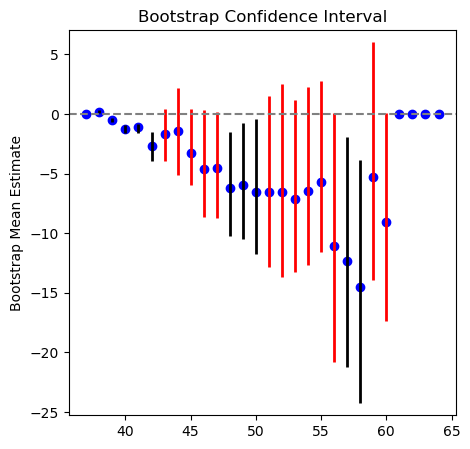

In [19]:
# Compute ensemble differences
ens_diff = UH2-UH

length=np.size(ens_diff,axis=1)
mean_m1=np.zeros(length)
low_m1=np.zeros(length)
high_m1=np.zeros(length)

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
for i in range(0,length):
    # Convert to DataFrame
    df = pd.DataFrame({"errore": ens_diff[:,i]})

    # Perform bootstrap with 10,000 resamples
    res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')
    
    # Extract mean and confidence intervals
    mean_m1[i] = np.mean(df["errore"])
    low_m1[i], high_m1[i] = res.confidence_interval

# Supponiamo che time_no, low_m1, high_m1 siano array NumPy
mask = (low_m1 <= 0) & (high_m1 >= 0)  # Seleziona solo gli indici che rispettano la condizione
mask_n = (low_m1 < 0) & (high_m1 < 0)
mask_p = (low_m1 > 0) & (high_m1 > 0)

# Applica la maschera ai dati
filtered_time = time[mask]
filtered_low = low_m1[mask]
filtered_high = high_m1[mask]


filtered_time_n = time[mask_n]
filtered_low_n = low_m1[mask_n]
filtered_high_n = high_m1[mask_n]

filtered_time_p = time[mask_p]
filtered_low_p = low_m1[mask_p]
filtered_high_p = high_m1[mask_p]

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(time, mean_m1, color="blue", label="Bootstrap Mean")
# Plotta solo i valori che soddisfano la condizione
plt.vlines(filtered_time, filtered_low, filtered_high, colors="red", linewidth=2)
plt.vlines(filtered_time_n, filtered_low_n, filtered_high_n, colors="black", linewidth=2)
plt.vlines(filtered_time_p, filtered_low_p, filtered_high_p, colors="black", linewidth=2)

plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
#plt.xlim(0.5, 1.5)
#plt.xlim(6, 10)
plt.ylim(np.min(low_m1) - 1, np.max(high_m1) + 1)
#plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
#plt.legend(["CI Crosses Zero" if (low_m1[i] <= 0 <= high_m1[i]) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

plt.show()

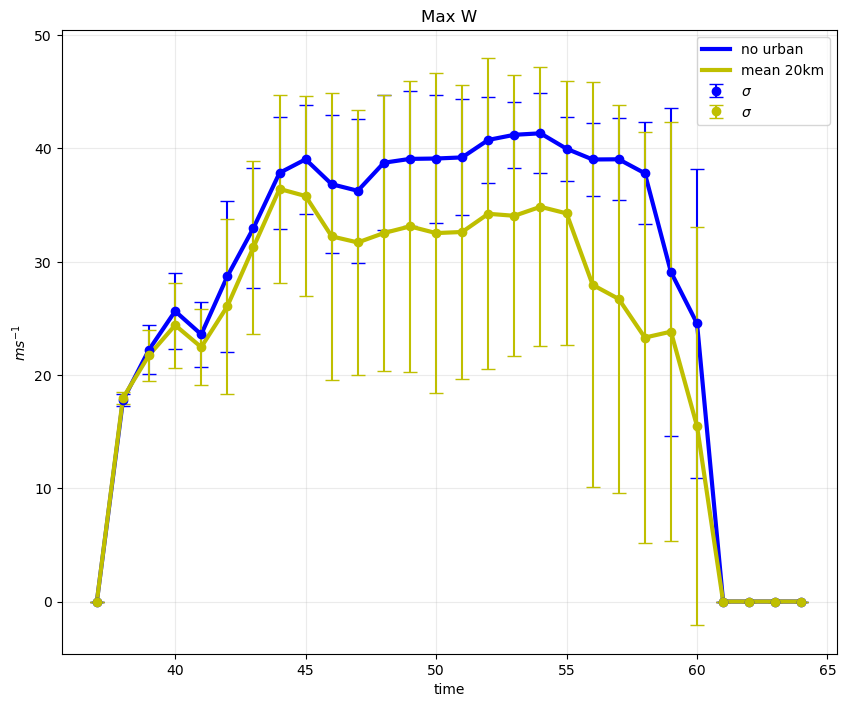

In [20]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
# ax.plot(time,UH_mean3,'g-',linewidth=3, label='mean 30km')
# ax.errorbar(time, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
#ax.set_ylim(0,50)
#ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

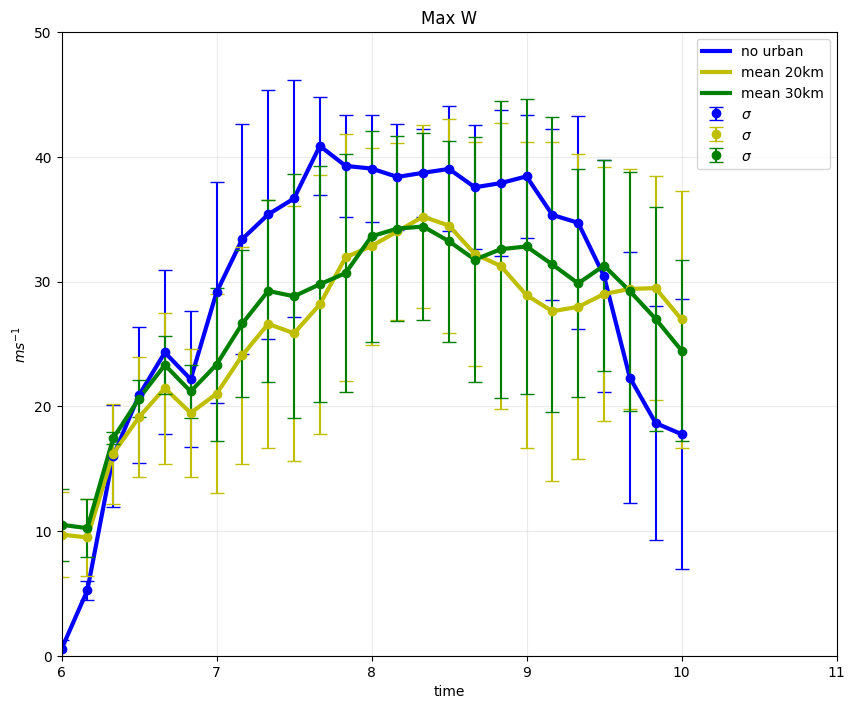

In [1487]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

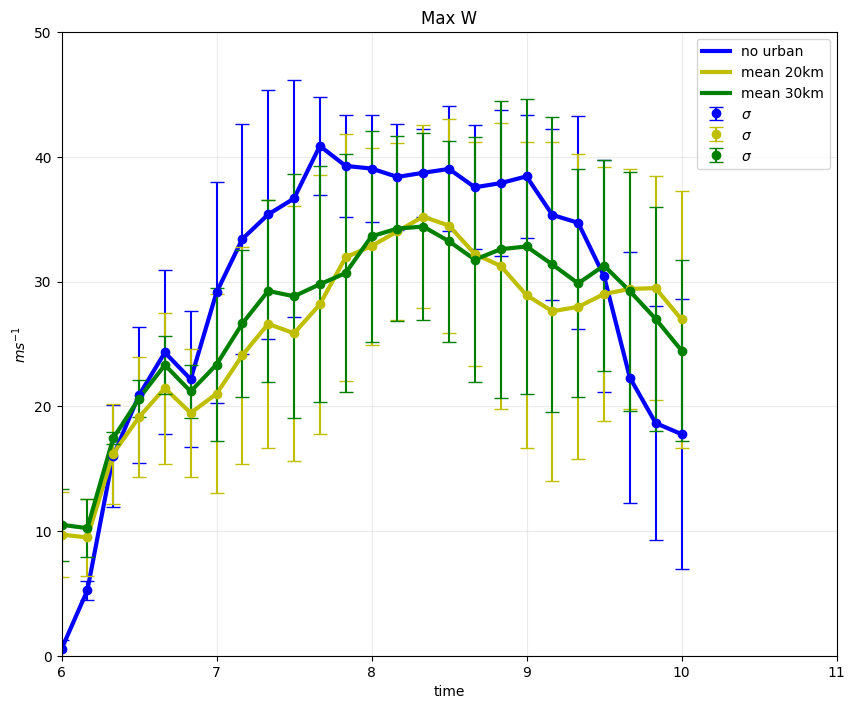

In [1487]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)

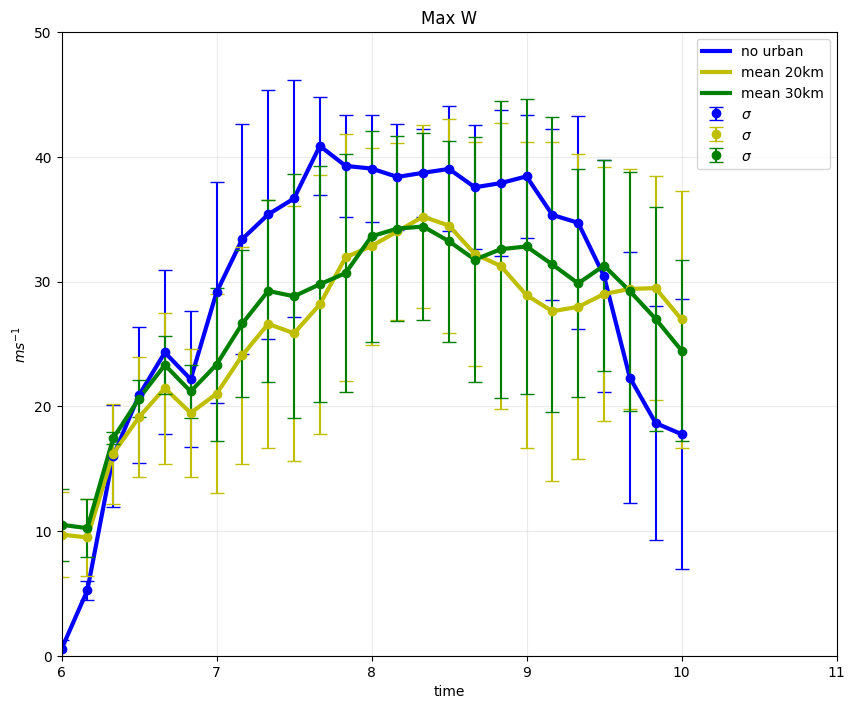

In [1487]:
fig=plt.figure(figsize=(10,8.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.plot(time_no,UH_mean,'b-',linewidth=3, label='no urban')
ax.errorbar(time_no, UH_mean, yerr=UH_std, fmt='o', color='b',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean2,'y-',linewidth=3, label='mean 20km')
ax.errorbar(time_no, UH_mean2, yerr=UH_std2, fmt='o', color='y',capsize=5, label="$\sigma$")
ax.plot(time_no,UH_mean3,'g-',linewidth=3, label='mean 30km')
ax.errorbar(time_no, UH_mean3, yerr=UH_std3, fmt='o', color='g',capsize=5, label="$\sigma$")

# for i in range(0,10):
#     ax.plot(time_no,UH[i,:],'k-',linewidth=1)
#     ax.plot(time_no,UH2[i,:],'g-',linewidth=1)
# ax.plot(time_no,UH_1,'g-',linewidth=1,label='1')
# ax.plot(time_no,UH_3,'b-',linewidth=1,label='3')
# ax.plot(time_no,UH_4,'y-',linewidth=1,label='4')
# ax.plot(time_10,UH_10,'k-',linewidth=1.5,label='10x10')
# ax.plot(time_20,UH_20,'k-',linewidth=2,label='20x20')
# ax.plot(time_30,UH_30,'k-',linewidth=2.5,label='30x30')
# ax.plot(time_40,UH_40,'k-',linewidth=3,label='40x40')
# ax.plot(time_50,UH_50,'k-',linewidth=4,label='50x50')
# plt.axvline(x = 25.5, color = 'b', label = 'city impact')
# plt.axvline(x = 26.0, color = 'b')
ax.set_ylim(0,50)
ax.set_xlim(6,11)
ax.set_ylabel('$ms^{-1}$')
ax.set_xlabel('time')
ax.legend()
ax.grid(alpha=0.25)
plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/no_urban/"+var+".png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)